In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#Chargement des données 
df =pd.read_csv("Auto Sales data.csv")

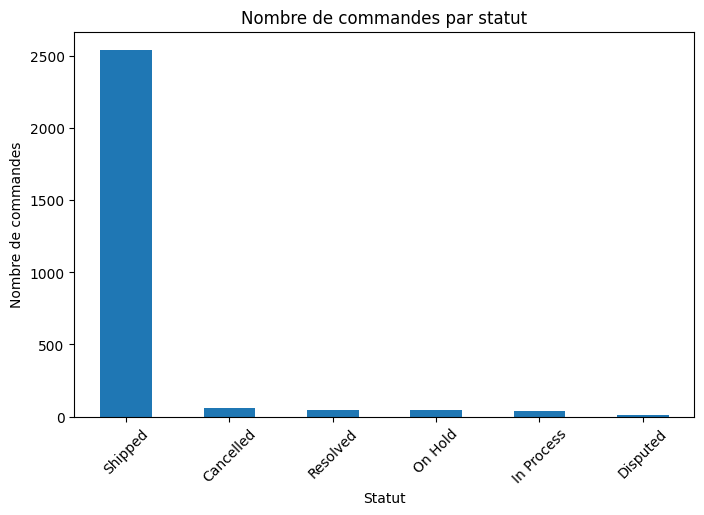

In [3]:
#Répartition des statuts 
status_counts = df['STATUS'].value_counts()

status_counts.plot(kind="bar", figsize=(8,5))
plt.title("Nombre de commandes par statut")
plt.xlabel("Statut")
plt.ylabel("Nombre de commandes")
plt.xticks(rotation=45)
plt.show()

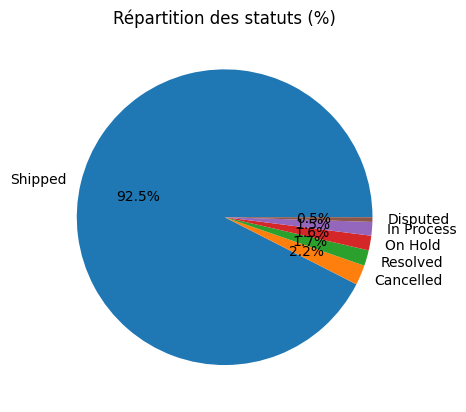

In [4]:
#Répartition en pourcentage
status_percent = df['STATUS'].value_counts(normalize=True)*100

status_percent.plot(kind="pie", autopct="%1.1f%%")
plt.title("Répartition des statuts (%)")
plt.ylabel("")
plt.show()

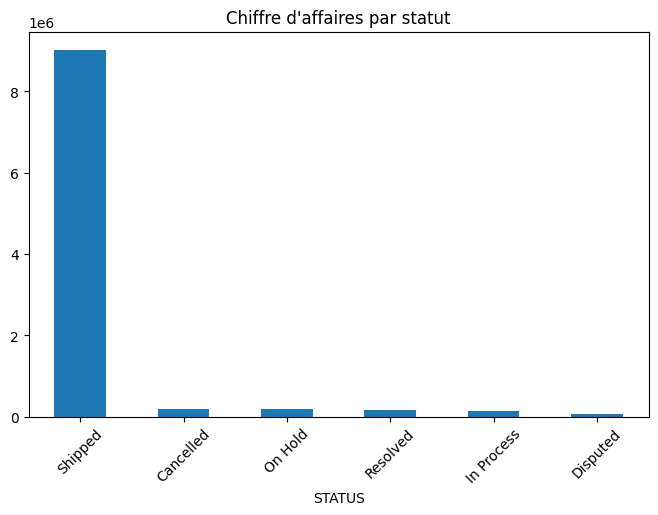

In [5]:
#CA par statut
sales_by_status = df.groupby("STATUS")["SALES"].sum().sort_values(ascending=False)

sales_by_status.plot(kind="bar", figsize=(8,5))
plt.title("Chiffre d'affaires par statut")
plt.xticks(rotation=45)
plt.show()

In [6]:
#Taux d'annulation
total_orders = len(df)
cancelled_orders = len(df[df["STATUS"] == "Cancelled"])

cancellation_rate = (cancelled_orders / total_orders) * 100

print(f"Taux d'annulation : {cancellation_rate:.2f}%")

Taux d'annulation : 2.18%


C:\Users\DC\AppData\Local\Temp\ipykernel_18120\272778957.py:4: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"])


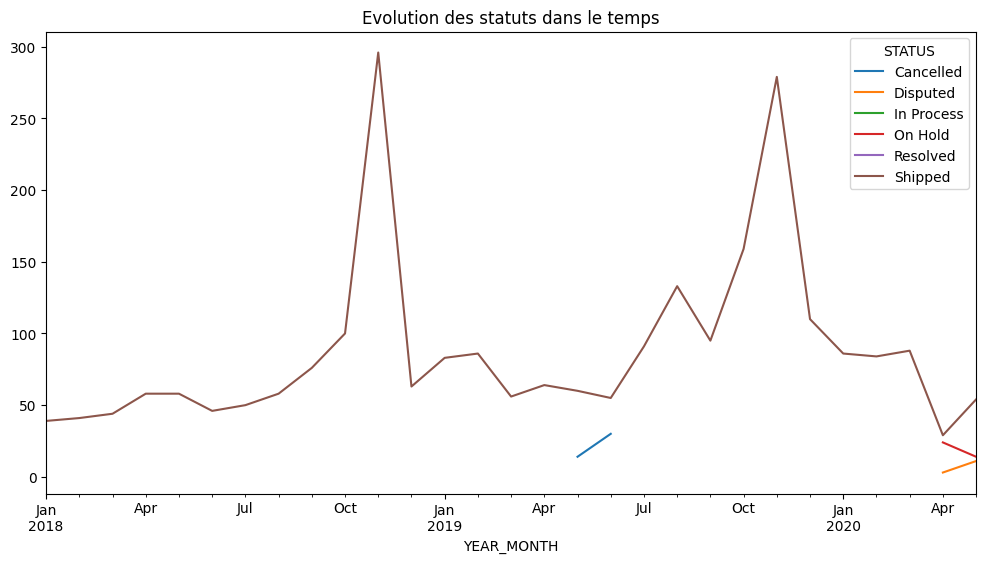

In [8]:
#Analyse des statuts dans le temps

#Préparation des données temporelles
df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"])

df["YEAR"] = df["ORDERDATE"].dt.year
df["MONTH"] = df["ORDERDATE"].dt.month
df["YEAR_MONTH"] = df["ORDERDATE"].dt.to_period("M")

status_time = df.groupby(["YEAR_MONTH", "STATUS"])["ORDERNUMBER"].count().unstack()

status_time.plot(figsize=(12,6))
plt.title("Evolution des statuts dans le temps")
plt.show()

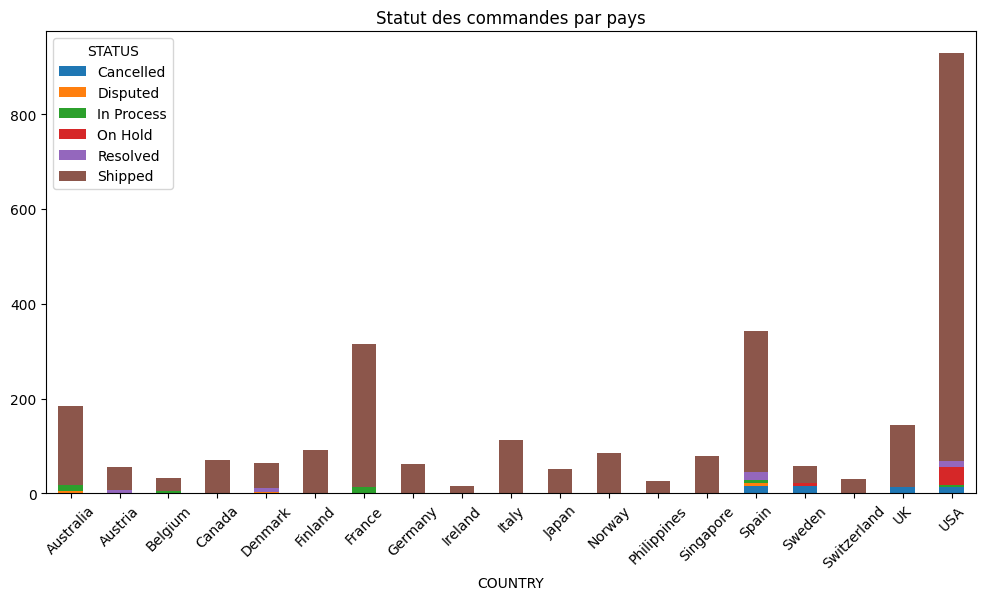

In [9]:
#Statut par pays
status_country = pd.crosstab(df["COUNTRY"], df["STATUS"])

status_country.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Statut des commandes par pays")
plt.xticks(rotation=45)
plt.show()

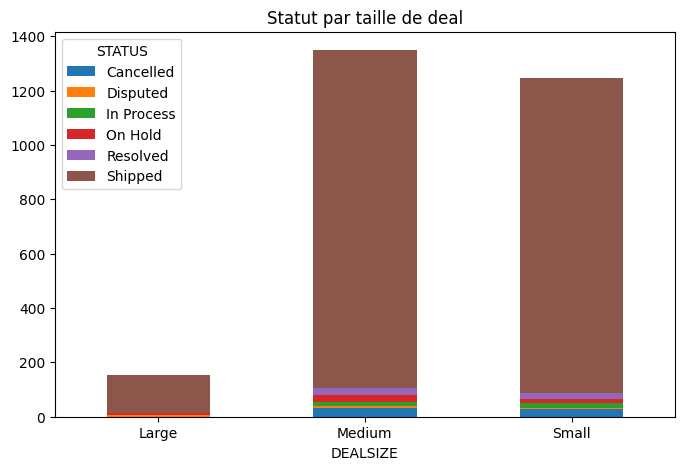

In [10]:
#Statut par taille de deal
status_deal = pd.crosstab(df["DEALSIZE"], df["STATUS"])

status_deal.plot(kind="bar", stacked=True , figsize=(8,5))
plt.title("Statut par taille de deal")
plt.xticks(rotation=0)
plt.show()

In [11]:
#Impact des statuts sur le CA réel
valid_sales = df[df["STATUS"] == "Shipped"]["SALES"].sum()
total_sales = df["SALES"].sum()

realization_rate = (valid_sales / total_sales) * 100

print(f"Taux de réalisation du CA : {realization_rate:.2f}%")

Taux de réalisation du CA : 92.41%
